# 05 — Data exploration (CASEN + SII) for BFM

Explores CASEN 2017/2022 + SII tax tabulations for Blanchet et al. (2022). Logic in `source/casen.py` / `source/sii.py`, plots in `source/figures.py`.


In [1]:
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from utils import load_root
ROOT = load_root()
from source.casen import income_overview, summarize_income, to_household, INCOME_COLS, WEIGHT_COL
from source.figures import plot_income_distribution, save_fig, plot_income_lorenz_comparison
from source.figures import plot_sii_brackets_comparison

%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set


In [2]:
OUTPUTFIG = ROOT / 'figures/p3'
OUTPUTDATA = ROOT / 'data/processed' 

In [3]:
# Load — convert_categoricals=False avoids duplicate label error on rama4_sub_rev3
casen_2017 = pd.read_stata(ROOT / 'data/CASEN/casen_2017.dta', convert_categoricals=False)
casen_2022 = pd.read_stata(ROOT / 'data/CASEN/casen_2022.dta', convert_categoricals=False)
print(casen_2017.shape, casen_2022.shape)

(216439, 840) (202231, 959)


## 1. Which columns for BFM?

**BFM needs:** continuous income + survey weights. In CASEN the canonical choices are:
- **Household income (preferred for BFM):** `ytotcorh` / `yautcorh` (household totals, corrected for non-response) and `ypchtotcor` (per-capita). One row per `folio+hogar`.
- **Person-level fallbacks:** `ytotcor` / `yautcor` / `ytot` / `yaut`.
- **Weight:** `expr` (expansion factor; `expr_div` is alternative). Always use `expr`.
For wealth we have no SII tabulation, so BFM is illustrated on **income** only. Below we show both levels; for the report use `ytotcorh` at household level.


In [4]:
income_overview(casen_2017).round(2)


,n,n_missing,pct_missing,mean,median,min,max
column,,,,,,,
yaut,115244,101195,46.75,485739.10,300000.0,42.0,84700000.0
ytot,144706,71733,33.14,403988.01,270000.0,83.0,84700000.0
yautcor,120486,95953,44.33,493962.23,305000.0,42.0,84700000.0
ytotcor,149282,67157,31.03,415297.93,274932.0,83.0,84700000.0
yauth,216439,0,0.00,883161.83,580000.0,0.0,87050000.0
ytoth,216439,0,0.00,1099657.98,770000.0,0.0,89050000.0
yautcorh,216439,0,0.00,945506.27,620000.0,0.0,87050000.0
ytotcorh,216439,0,0.00,1164452.15,821000.0,0.0,89050000.0
ypchtotcor,216439,0,0.00,345515.02,232823.0,0.0,48898332.0


In [5]:
income_overview(casen_2022).round(2)


,n,n_missing,pct_missing,mean,median,min,max
column,,,,,,,
yaut,112553,89678,44.34,613474.13,420000.0,167.0,63500000.0
ytot,202231,0,0.00,371519.94,200000.0,0.0,63740000.0
yautcor,115217,87014,43.03,616374.69,422567.0,167.0,63500000.0
ytotcor,202231,0,0.00,381253.80,205000.0,0.0,63740000.0
yauth,202231,0,0.00,1095947.78,773334.0,0.0,76500000.0
ytoth,202231,0,0.00,1424668.90,1079472.0,0.0,77300000.0
yautcorh,202231,0,0.00,1132364.17,800000.0,0.0,76500000.0
ytotcorh,202111,120,0.06,1476988.84,1121667.0,0.0,77300000.0
ypchtotcor,202111,120,0.06,471122.40,349778.0,0.0,35143333.0


### Choice for the paper
Use `ytotcorh` (total household income, corrected) collapsed to one row per household (`folio`, `hogar`) with weight `expr`. For per-capita inequality use `ypchtotcor`. Avoid `yaut` (autonomous income only, many NaNs: ~47% missing in 2017) and uncorrected `ytot`/`yaut`.


## 2. Missingness


In [6]:
import numpy as np
# heatmap-style table
for name, df in [("2017", casen_2017), ("2022", casen_2022)]:
    print(f"\n{name} — key cols missing %")
    for c in ["ytotcorh","yautcorh","ypchtotcor","ytotcor","yautcor","expr"]:
        if c in df.columns:
            print(f"{c:12s} {df[c].isna().mean()*100:5.2f}%  n={df[c].notna().sum():,}")



2017 — key cols missing %
ytotcorh      0.00%  n=216,439
yautcorh      0.00%  n=216,439
ypchtotcor    0.00%  n=216,439
ytotcor      31.03%  n=149,282
yautcor      44.33%  n=120,486
expr          0.00%  n=216,439

2022 — key cols missing %
ytotcorh      0.06%  n=202,111
yautcorh      0.00%  n=202,231
ypchtotcor    0.06%  n=202,111
ytotcor       0.00%  n=202,231
yautcor      43.03%  n=115,217
expr          0.00%  n=202,231


## 3. Summary table (weighted)


In [7]:
# Household-level weighted stats for ytotcorh
for name, df in [("2017", casen_2017), ("2022", casen_2022)]:
    hh = to_household(df, income_col="ytotcorh", weight_col="expr")
    s = summarize_income(hh, income_col="ytotcorh", weight_col="expr")
    display(pd.DataFrame([s]).T.rename(columns={0: name}))


,2017
n_obs,7.094800e+04
n_missing,0.000000e+00
weighted_mean,1.171150e+06
weighted_median,8.000000e+05
p10,3.383300e+05
p25,5.034150e+05
p75,1.322950e+06
p90,2.254646e+06
p99,6.599833e+06
share_zero,1.268535e-01


,2022
n_obs,7.205300e+04
n_missing,3.000000e+00
weighted_mean,1.566224e+06
weighted_median,1.111417e+06
p10,4.847500e+05
p25,7.150780e+05
p75,1.800000e+06
p90,2.998084e+06
p99,8.325000e+06
share_zero,2.636948e-01


## 4. Plots


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p3/casen_income_dist.pdf


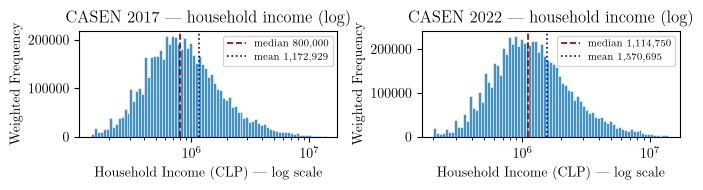

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2))
for ax, (name, df) in zip(axes, [("2017", casen_2017), ("2022", casen_2022)]):
    hh = to_household(df, income_col="ytotcorh", weight_col="expr")
    plot_income_distribution(hh, fig, ax, income_col="ytotcorh", weight_col="expr", bins=80, log_x=True)
    ax.set_title(f"CASEN {name} — household income (log)")
plt.tight_layout()
save_fig(OUTPUTFIG / "casen_income_dist.pdf", fig)
plt.show()


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p3/casen_lorenz.pdf


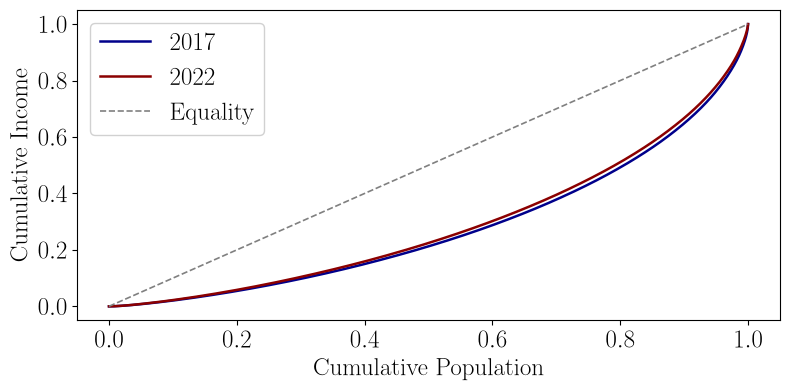

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
hh17 = to_household(casen_2017, income_col="ytotcorh", weight_col="expr")
hh22 = to_household(casen_2022, income_col="ytotcorh", weight_col="expr")
fig, ax = plot_income_lorenz_comparison([hh17, hh22], ["2017","2022"], fig, ax, income_col="ytotcorh", weight_col="expr", fontsize=18)
plt.tight_layout()
save_fig(OUTPUTFIG / "casen_lorenz.pdf", fig)
plt.show()


## 5. SII tax tabulations (for BFM)

Uses `PUB_Total.xlsb` from `https://www.sii.cl/sobre_el_sii/estadisticas_de_personas_naturales.html` (personas naturales, 2005-2024, updated Oct 2025). Place the file at `data/SII/PUB_Total.xlsb`. The sheet contains brackets by UTA with `N° contribuyentes | Renta total MM$` per AT. For BFM we need **AT 2018 (commercial 2017)** and **AT 2023 (commercial 2022)**.


In [10]:
from source.sii import load_sii_pub_total, sii_for_at, sii_summary_for_report
from source.figures import plot_sii_brackets
import pandas as pd
sii_path = ROOT / "data/SII/PUB_Total.xlsb"
print(f"Looking for {sii_path} — exists: {sii_path.exists()}")
if sii_path.exists():
    raw, cleaned = load_sii_pub_total(sii_path)
    display(raw.iloc[6:13])  # header + first rows
    print("\nCleaned head (tidy):")
    display(cleaned.head(10))
    print(f"Years: {sorted(cleaned['año_comercial'].dropna().unique().tolist())[:5]} ... {sorted(cleaned['año_comercial'].dropna().unique().tolist())[-5:]}")
    display(cleaned[cleaned['año_comercial'].isin([2017,2022])])
else:
    print("Download PUB_Total.xlsb from SII and place it in data/SII/")


Looking for /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/data/SII/PUB_Total.xlsb — exists: True


,0,1,2,3,4,5,6,7,8,9,10
6,NaN,NaN,Per. Naturales contribuyentes de GC,NaN,NaN,Per. Naturales contribuyentes de 2a Cat.,NaN,NaN,Consolidado,NaN,NaN
7,Año Comercial,Tramo de Rentas,N° de Personas,Renta Determinada (Millones de pesos),Impuesto Determinado (Millones de pesos),N° de Personas,Renta Determinada (Millones de pesos),Impuesto Determinado (Millones de pesos),N° de Personas,Renta Determinada (Millones de pesos),Impuesto Determinado (Millones de pesos)
8,2005,"Tramo 1 - 0 a 13,5 UTA (Exento)",1187092,1841095.5,0.4,4724828,7188161.1,3916.4,5911920,9029256.6,3916.8
9,2005,"Tramo 2 - 13,5 a 30 UTA (Tasa 5%)",322135,2472518.3,41215.4,413610,2925446.7,42772.4,735745,5397965,83987.8
10,2005,Tramo 3 - 30 a 50 UTA (Tasa 10%),142946,2083438.2,90504.4,62507,887777.5,39339,205453,2971215.7,129843.4
11,2005,Tramo 4 - 50 a 70 UTA (Tasa 15%),66630,1490365.4,105485.4,16456,361229.6,26540.8,83086,1851595,132026.2
12,2005,Tramo 5 - 70 a 90 UTA (Tasa 25%),35707,1068066.5,109000.5,5667,168644.4,18018.3,41374,1236710.9,127018.8



Cleaned head (tidy):


,año_comercial,tramo,gc_n,gc_renta,gc_impuesto,cat2_n,cat2_renta,cat2_impuesto,cons_n,cons_renta,cons_impuesto
8,2005,"Tramo 1 - 0 a 13,5 UTA (Exento)",1187092,1841095.5,0.4,4724828,7188161.1,3916.4,5911920,9029256.6,3916.8
9,2005,"Tramo 2 - 13,5 a 30 UTA (Tasa 5%)",322135,2472518.3,41215.4,413610,2925446.7,42772.4,735745,5397965.0,83987.8
10,2005,Tramo 3 - 30 a 50 UTA (Tasa 10%),142946,2083438.2,90504.4,62507,887777.5,39339.0,205453,2971215.7,129843.4
11,2005,Tramo 4 - 50 a 70 UTA (Tasa 15%),66630,1490365.4,105485.4,16456,361229.6,26540.8,83086,1851595.0,132026.2
12,2005,Tramo 5 - 70 a 90 UTA (Tasa 25%),35707,1068066.5,109000.5,5667,168644.4,18018.3,41374,1236710.9,127018.8
13,2005,Tramo 6 - 90 a 120 UTA (Tasa 32%),24220,942535.5,136586.8,3353,129935.5,19333.3,27573,1072471.0,155920.1
14,2005,Tramo 7 - 120 a 150 UTA (Tasa 37%),9460,476080.1,90166.5,1350,68153.3,13337.9,10810,544233.4,103504.4
15,2005,Tramo 8 - Más de 150 UTA (Tasa 40%),10505,1058296.2,309593.4,3402,306333.1,86717.8,13907,1364629.3,396311.2
16,2006,"Tramo 1 - 0 a 13,5 UTA (Exento)",1200646,1945296.6,3.0,4940688,7836081.6,4394.3,6141334,9781378.2,4397.3
17,2006,"Tramo 2 - 13,5 a 30 UTA (Tasa 5%)",344819,2702689.6,45158.4,442420,3190333.2,47188.8,787239,5893022.8,92347.2


Years: [2005, 2006, 2007, 2008, 2009] ... [2020, 2021, 2022, 2023, 2024]


,año_comercial,tramo,gc_n,gc_renta,gc_impuesto,cat2_n,cat2_renta,cat2_impuesto,cons_n,cons_renta,cons_impuesto
104,2017,"Tramo 1 - 0 a 13,5 UTA (Exento)",1787408,5528615.2,2.3,5734340,15251554.8,31409.6,7521748,20780170.0,31411.9
105,2017,"Tramo 2 - 13,5 a 30 UTA (Tasa 4%)",988466,11156393.9,145335.6,614470,6449999.4,77482.1,1602936,17606393.3,222817.7
106,2017,Tramo 3 - 30 a 50 UTA (Tasa 8%),363918,7841939.5,270361.2,87728,1833342.5,61890.3,451646,9675282.0,332251.5
107,2017,"Tramo 4 - 50 a 70 UTA (Tasa 13,5%)",153693,5096073.8,298902.9,17549,572254.0,33513.7,171242,5668327.8,332416.6
108,2017,Tramo 5 - 70 a 90 UTA (Tasa 23%),80300,3574885.4,317919.7,5517,243775.8,21062.4,85817,3818661.2,338982.1
109,2017,"Tramo 6 - 90 a 120 UTA (Tasa 30,4%)",60665,3530469.2,464432.8,3566,206748.4,25229.1,64231,3737217.6,489661.9
110,2017,Tramo 7 - Más de 120 UTA (Tasa 35%),75350,9601729.8,2369125.3,8037,986531.0,214109.2,83387,10588260.8,2583234.5
141,2022,"Tramo 1 - 0 a 13,5 UTA (Exento)",2039070,9000501.3,1.3,6406722,23633686.5,69677.0,8445792,32634187.8,69678.3
142,2022,"Tramo 2 - 13,5 a 30 UTA (Tasa 4%)",1272145,18704196.6,243870.0,678338,9222893.5,130964.4,1950483,27927090.1,374834.4
143,2022,Tramo 3 - 30 a 50 UTA (Tasa 8%),457759,12824591.0,441191.9,81428,2211339.4,85154.3,539187,15035930.4,526346.2


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p3/sii_brackets_comparison.pdf


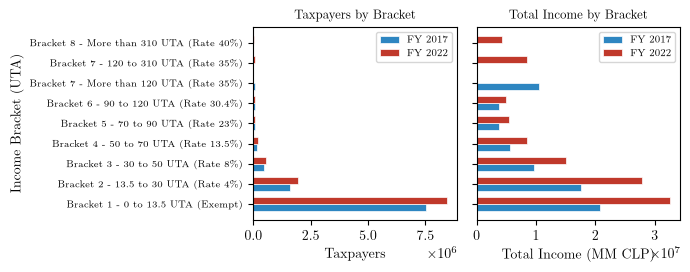

{'año_comercial': 2017, 'at': 2018, 'total_n': 9981007, 'total_renta_mm': 71874312.7, 'top_tramo': 'Tramo 7 - Más de 120 UTA (Tasa 35%)', 'top_n': 83387, 'top_renta_mm': 10588260.8, 'top_n_share': 0.008354567830680813, 'top_renta_share': 0.14731634157247392}
{'año_comercial': 2022, 'at': 2023, 'total_n': 11367847, 'total_renta_mm': 107140360.2, 'top_tramo': 'Tramo 8 - Más de 310 UTA (Tasa 40%)', 'top_n': 9749, 'top_renta_mm': 4228145.1, 'top_n_share': 0.0008575942304642207, 'top_renta_share': 0.0394636072914752}


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3), sharey=True)

if sii_path.exists():
    plot_sii_brackets_comparison(cleaned, fig, axes, at_list=(2017, 2022), value=None)
    plt.tight_layout(rect=[0,0,1,0.94])
    save_fig(ROOT / "figures/p3/sii_brackets_comparison.pdf", fig)
    plt.show()
    # Also keep single-year summary
    print(sii_summary_for_report(cleaned, 2017))
    print(sii_summary_for_report(cleaned, 2022))
else:
    print("Skipping plot — add PUB_Total.xlsb first")


## 6. Saving Data (for BFM)


In [12]:
# Save household-level data for BFM replication (ytotcorh + weights)
OUTPUTDATA.mkdir(parents=True, exist_ok=True)
for name, df in [("2017", casen_2017), ("2022", casen_2022)]:
    hh = to_household(df, income_col="ytotcorh", weight_col="expr")
    cols = [c for c in ["folio","hogar","ytotcorh","yautcorh","ypchtotcor","ytotcor","expr","tot_per_h","region","area"] if c in hh.columns]
    hh_out = hh[cols].copy()
    hh_out = hh_out.dropna(subset=["ytotcorh"])
    hh_out = hh_out[hh_out["ytotcorh"] >= 0]
    parquet = OUTPUTDATA / f"casen_{name}_hh.parquet"
    csv = OUTPUTDATA / f"casen_{name}_hh.csv"
    hh_out.to_parquet(parquet, index=False)
    hh_out.to_csv(csv, index=False)
    print(f"{name}: saved {len(hh_out):,} hh -> {parquet.name} + {csv.name}  (cols: {', '.join(cols)})")
    person_cols = [c for c in ["folio","hogar","ytotcor","yautcor","expr","region","area"] if c in df.columns]
    df[person_cols].to_parquet(OUTPUTDATA / f"casen_{name}_person.parquet", index=False)
    print(f"  person-level saved -> casen_{name}_person.parquet")


2017: saved 70,948 hh -> casen_2017_hh.parquet + casen_2017_hh.csv  (cols: folio, hogar, ytotcorh, expr, tot_per_h, region, area)
  person-level saved -> casen_2017_person.parquet
2022: saved 72,053 hh -> casen_2022_hh.parquet + casen_2022_hh.csv  (cols: folio, hogar, ytotcorh, expr, tot_per_h, region, area)
  person-level saved -> casen_2022_person.parquet
